# 9. 의사결정나무 분류 기초 (Decision Tree)

Iris 데이터셋을 이용해 `DecisionTreeClassifier`의 학습, 주요 하이퍼파라미터(`criterion`, `max_depth`, `min_samples_split`, `min_samples_leaf`), 트리 시각화(`plot_tree`) 및 텍스트 규칙(`export_text`) 추출 방법을 학습합니다.

원본 노트북 Lv2_Python_1118_DecisionTree.ipynb

**Decision Tree(의사결정나무)**

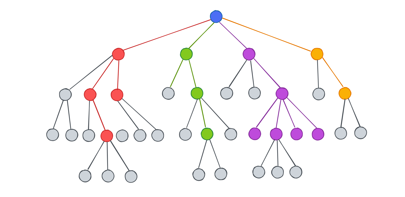

In [30]:
# 패키지 import
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt



In [31]:
# Iris data 로드
iris = load_iris()
X = iris.data
y = iris.target

In [32]:
# 데이터 분활
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
# 모델 초기화 - Initialize the Decision Tree Classifier
# 모델 학습을 위한 초기 객체 생성

# clf = DecisionTreeClassifier(criterion = 'entropy' random_state=42)
# clf = DecisionTreeClassifier(random_state=42, max_depth = 2)
clf = DecisionTreeClassifier(random_state=42)

# Fit the model with the training data
clf.fit(X_train, y_train)

# Predict the test dataset
predictions = clf.predict(X_test)

- 도움말 등을 통해 help(DecisionTreeClassifier)모델 설정값(하이퍼파라메터)와 그 의미를 확인, 이해하기

In [34]:
## 도움말을 통해 모델 옵션(설정) 확인
help(DecisionTreeClassifier)

Help on class DecisionTreeClassifier in module sklearn.tree._classes:

class DecisionTreeClassifier(sklearn.base.ClassifierMixin, BaseDecisionTree)
 |  DecisionTreeClassifier(
 |      *,
 |      criterion='gini',
 |      splitter='best',
 |      max_depth=None,
 |      min_samples_split=2,
 |      min_samples_leaf=1,
 |      min_weight_fraction_leaf=0.0,
 |      max_features=None,
 |      random_state=None,
 |      max_leaf_nodes=None,
 |      min_impurity_decrease=0.0,
 |      class_weight=None,
 |      ccp_alpha=0.0,
 |      monotonic_cst=None
 |  )
 |
 |  A decision tree classifier.
 |
 |  Read more in the :ref:`User Guide <tree>`.
 |
 |  Parameters
 |  ----------
 |  criterion : {"gini", "entropy", "log_loss"}, default="gini"
 |      The function to measure the quality of a split. Supported criteria are
 |      "gini" for the Gini impurity and "log_loss" and "entropy" both for the
 |      Shannon information gain, see :ref:`tree_mathematical_formulation`.
 |
 |  splitter : {"best",

- 옵션 의미 확인 완료.
```python  

from sklearn.tree import DecisionTreeClassifier

DecisionTreeClassifier(
    # ===== Option = Default =====
    criterion='gini',               # 노드 분할의 불순도 평가 기준 ("gini", "entropy", "log_loss"), 기본값="gini"
    splitter='best',                # 각 노드의 분할 방식 ("best": 최적 분할, "random": 무작위 후보 중 최적 분할)
    max_depth=None,                 # 트리의 최대 깊이 (int, None), None이면 다른 종료 조건까지 확장
    min_samples_split=2,            # 내부 노드를 분할하기 위한 최소 샘플 수 (int, float), 기본값=2
    min_samples_leaf=1,             # 리프(말단) 노드에 반드시 포함되어야 하는 최소 샘플 수 (int, float), 기본값=1
    min_weight_fraction_leaf=0.0,   # 리프 노드가 가져야 하는 전체 샘플 가중치 대비 최소 비율 (float), 기본값=0.0
    max_features=None,              # 각 노드 분할 시 고려할 최대 특성 수 (int, float, "sqrt", "log2", None), None=전체 특성
    random_state=None,              # 난수 시드 설정 (int, None), 정수 지정 시 실행 결과의 재현성 확보
    max_leaf_nodes=None,            # 생성 가능한 최대 리프 노드 수 (int, None), None이면 제한 없음
    min_impurity_decrease=0.0,      # 노드 분할에 필요한 최소 불순도 감소량 (float), 값이 클수록 분할 제한
    class_weight=None,              # 클래스별 가중치 설정 (dict, "balanced", None), balanced=클래스 빈도에 반비례
    ccp_alpha=0.0,                  # 비용 복잡도 가지치기 강도 (float >= 0), 값이 클수록 트리 단순화
    monotonic_cst=None              # 특성별 단조성 제약 (1: 증가, 0: 제약 없음, -1: 감소, None: 전체 제약 없음)
)  

```

In [35]:
# DecisionTreeClassifier?

In [36]:
### 모델 기본 설정값 확인
clf.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [37]:
# 하이퍼파라미터 / 기본값 / 설명
# criterion	'gini'	분할 기준 (불순도)
# max_depth	None	끝까지 분할 (과적합 위험)
# min_samples_split	2	최소 분할 샘플 수
# min_samples_leaf	1	리프 노드 최소 샘플
# max_features	None	모든 feature 사용
# splitter	'best'	가장 좋은 분할 선택

In [38]:
# 모델 성능 - accuracy
accuracy = clf.score(X_test, y_test)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 100.00%


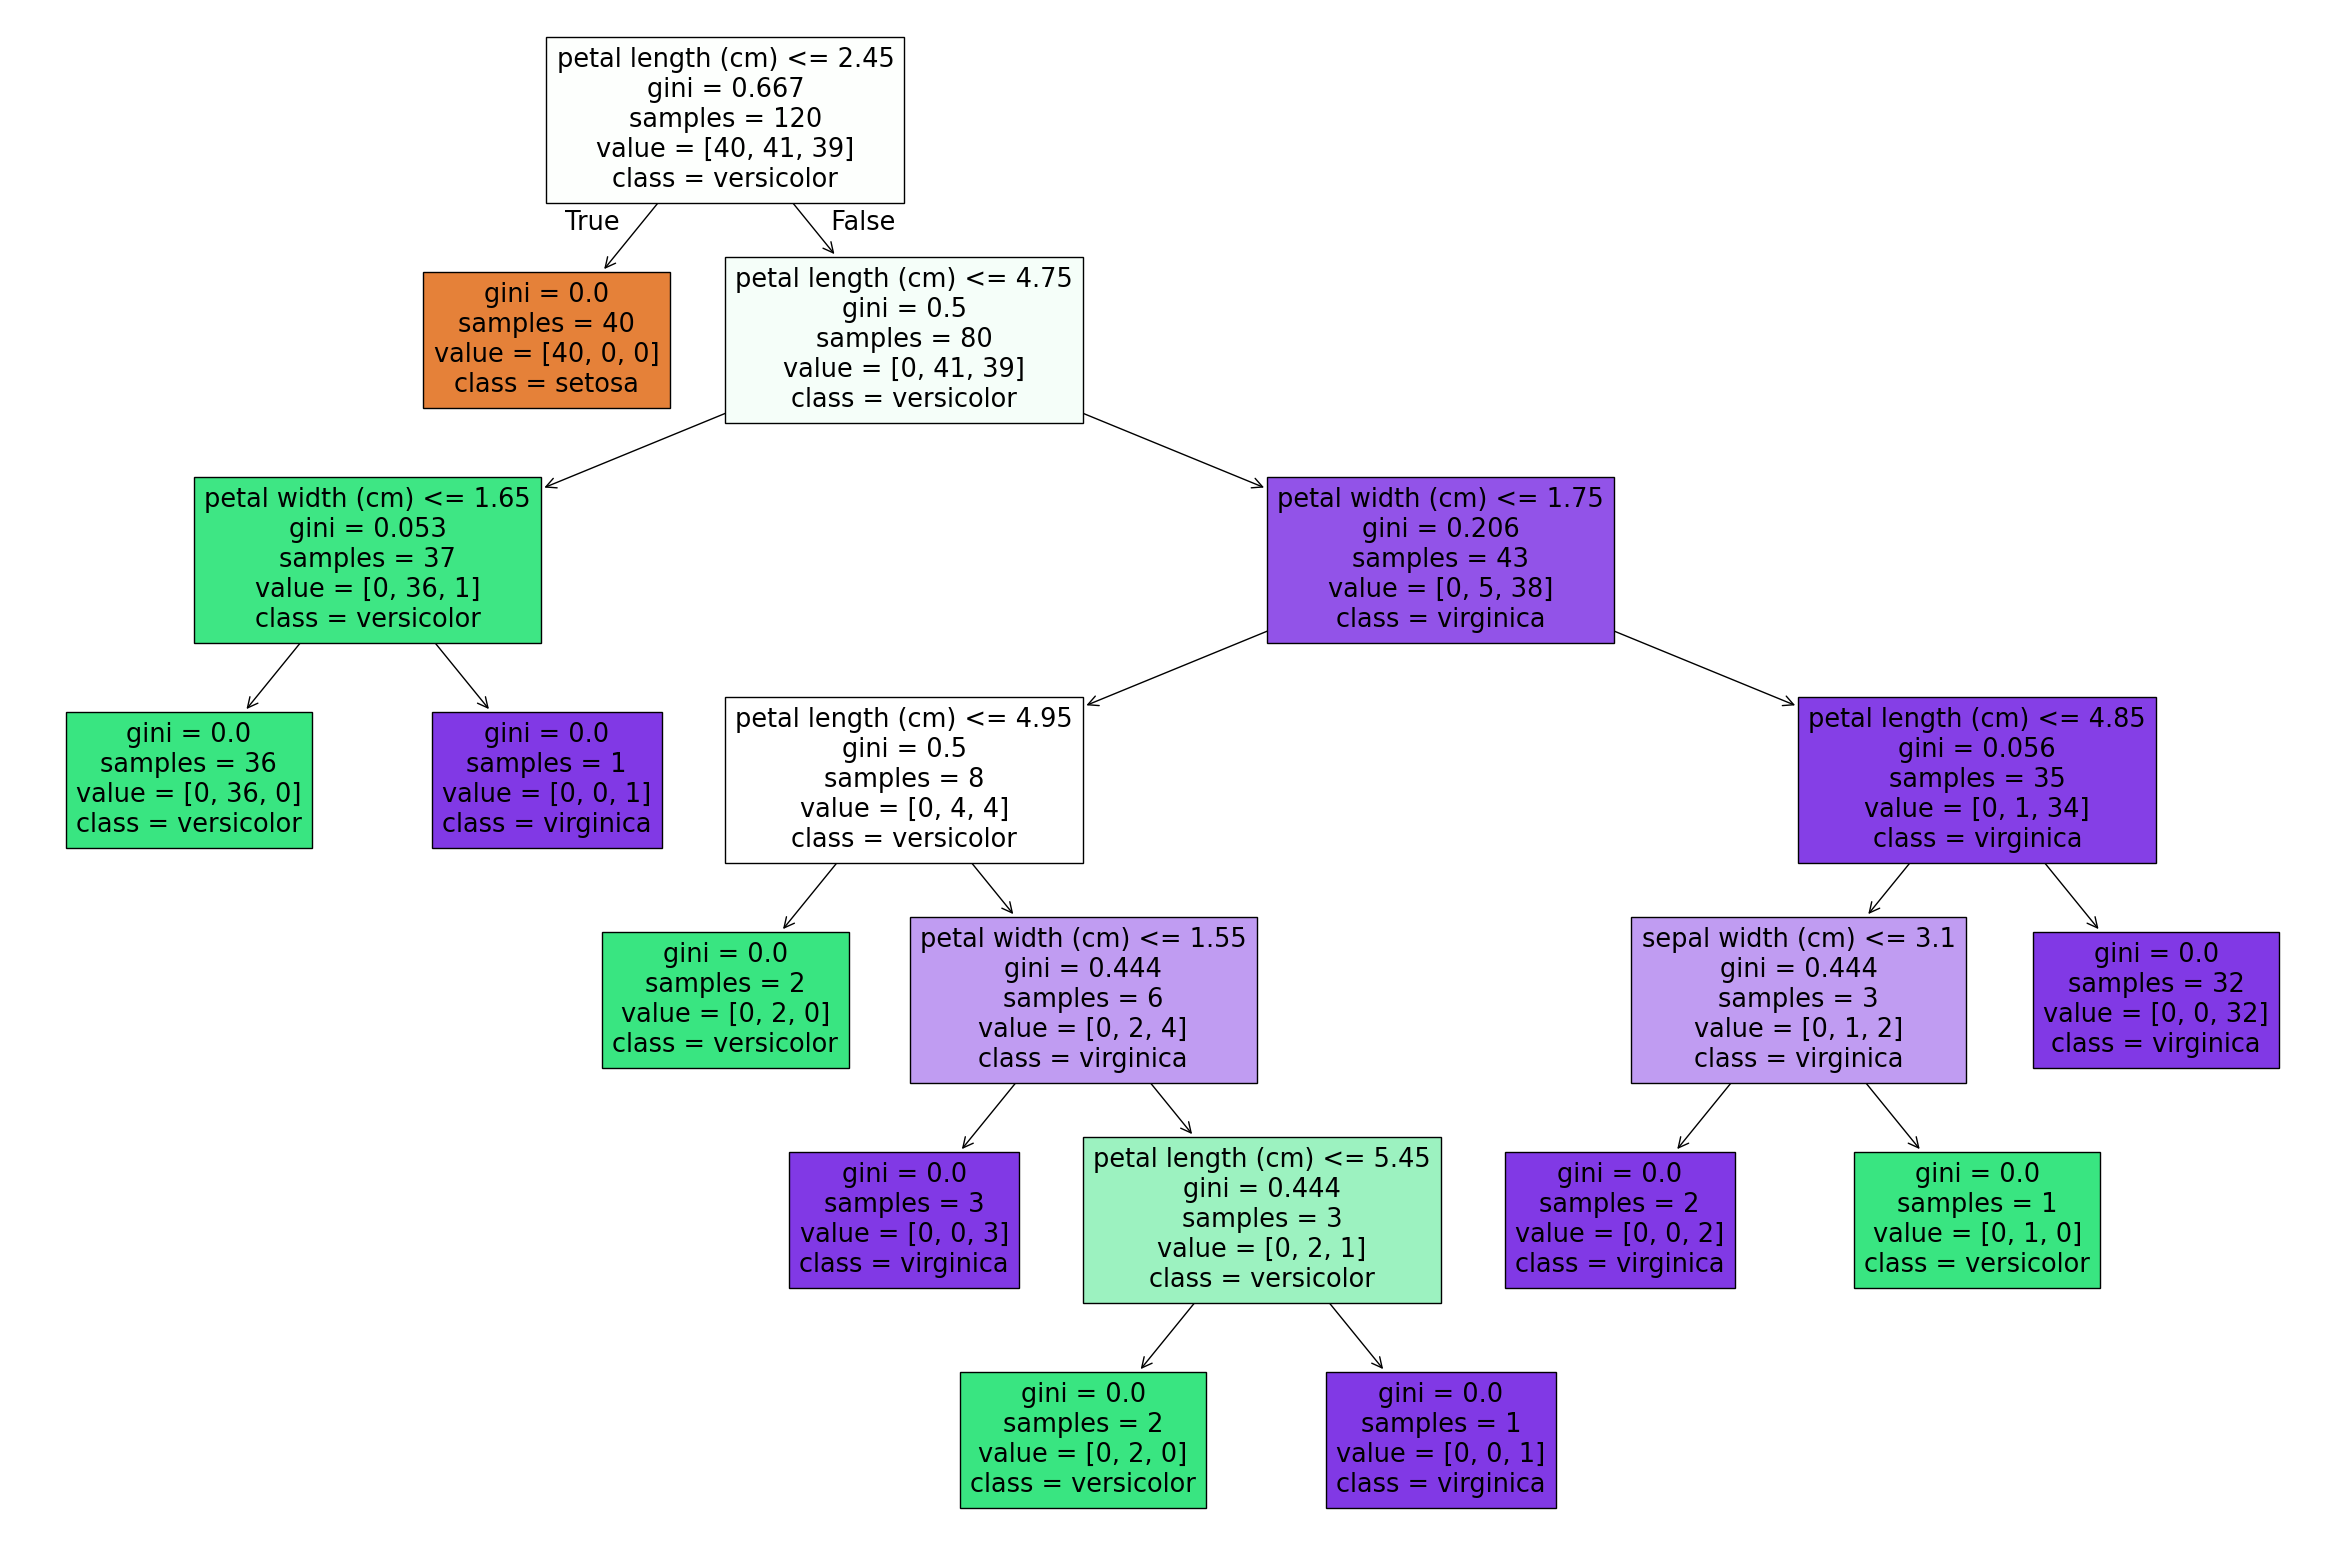

In [39]:
# 시각화
plt.figure(figsize=(30,20))
plot_tree(clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()

**결과 해석**

In [40]:
#  트리 규칙을 텍스트로 출력

from sklearn.tree import DecisionTreeClassifier, export_text

tree_rules = export_text(clf, feature_names=iris.feature_names)
print(tree_rules)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.75
|   |   |--- petal width (cm) <= 1.65
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.65
|   |   |   |--- class: 2
|   |--- petal length (cm) >  4.75
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- petal length (cm) <= 4.95
|   |   |   |   |--- class: 1
|   |   |   |--- petal length (cm) >  4.95
|   |   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |   |--- class: 2
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- petal length (cm) <= 4.85
|   |   |   |   |--- sepal width (cm) <= 3.10
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  3.10
|   |   |   |   |   |--- class: 1
|   |   |   |--- petal 